## Обработка с помощью MiXCR

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

archives = list(
    Path('/content/drive/MyDrive').rglob('BCR_homework.zip')
)

print("Найденные архивы:", archives)

assert archives, "Архив не найден на Google Диске"
ZIP_PATH = archives[0]

Найденные архивы: [PosixPath('/content/drive/MyDrive/Colab Notebooks/BCR_homework.zip')]


In [3]:
import zipfile

RAW_DIR = Path('/content/BCR_input')
RAW_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(ZIP_PATH) as archive:
    print("Содержимое архива:")
    for name in archive.namelist():
        print(name)

    archive.extractall(RAW_DIR)

Содержимое архива:
DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz
DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz


In [4]:
!wget -q --show-progress \
  https://github.com/milaboratory/mixcr/releases/download/v4.7.0/mixcr-4.7.0.zip \
  -O /content/mixcr.zip

!mkdir -p /content/mixcr_bin
!unzip -oq /content/mixcr.zip -d /content/mixcr_bin
!chmod +x /content/mixcr_bin/mixcr

/content/mixcr.zip  100%[===================>] 101.47M  96.7MB/s    in 1.0s    


In [5]:
from getpass import getpass
import subprocess

license_key = getpass("ключ:")

result = subprocess.run(
    ["/content/mixcr_bin/mixcr", "activate-license"],
    input=license_key + "\n",
    text=True,
    capture_output=True
)

print(result.stdout.replace(license_key, "[скрыто]"))
print(result.stderr.replace(license_key, "[скрыто]"))

del license_key

ключ:··········
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Please enter the license:
Checking the license...
Ok
License activated successfully.




In [6]:
import subprocess
R1 = next(RAW_DIR.rglob("*_R1.fastq.gz"))
R2 = next(RAW_DIR.rglob("*_R2.fastq.gz"))

#резы
RESULT_DIR = Path("/content/BCR_results")
RESULT_DIR.mkdir(exist_ok=True)

OUTPUT = RESULT_DIR / "BCR_sample"

#обработка BCR с учётом UMI
subprocess.run([
    "/content/mixcr_bin/mixcr",
    "analyze",
    "milab-human-rna-ig-umi-multiplex",
    str(R1),
    str(R2),
    str(OUTPUT)
], check=True)

CompletedProcess(args=['/content/mixcr_bin/mixcr', 'analyze', 'milab-human-rna-ig-umi-multiplex', '/content/BCR_input/DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz', '/content/BCR_input/DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz', '/content/BCR_results/BCR_sample'], returncode=0)

In [7]:
import shutil

DRIVE_RESULTS = Path("/content/drive/MyDrive/BCR_results")
DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)

# Копирую резы на диск
shutil.copytree(
    "/content/BCR_results",
    DRIVE_RESULTS,
    dirs_exist_ok=True
)

print("Результаты сохранены:", DRIVE_RESULTS)

Результаты сохранены: /content/drive/MyDrive/BCR_results


In [38]:
BCR_RESULTS = Path("/content/drive/MyDrive/BCR_results")

for f in sorted(BCR_RESULTS.iterdir()):
    print(f.name)

BCR_sample.align.report.json
BCR_sample.align.report.txt
BCR_sample.alignments.vdjca
BCR_sample.assemble.report.json
BCR_sample.assemble.report.txt
BCR_sample.clns
BCR_sample.clones_IGH.tsv
BCR_sample.qc.json
BCR_sample.qc.txt
BCR_sample.refine.report.json
BCR_sample.refine.report.txt
BCR_sample.refined.vdjca


In [40]:
report = (BCR_RESULTS / "BCR_sample.align.report.txt").read_text()
print(report)

Analysis date: Mon Nov 16 15:22:22 UTC 2026
Input file(s): /content/BCR_input/DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz,/content/BCR_input/DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz
Output file(s): /content/BCR_results/BCR_sample.alignments.vdjca
Version: 4.7.0; built=Wed Aug 07 19:19:48 UTC 2024; rev=976ba14139; lib=repseqio.v5.1
Command line arguments: align --report /content/BCR_results/BCR_sample.align.report.txt --json-report /content/BCR_results/BCR_sample.align.report.json --preset milab-human-rna-ig-umi-multiplex --save-output-file-names /content/BCR_results/BCR_sample.align.list.tsv /content/BCR_input/DChu_T7_pbmc_d7COVID2_2_R1.fastq.gz /content/BCR_input/DChu_T7_pbmc_d7COVID2_2_R2.fastq.gz /content/BCR_results/BCR_sample.alignments.vdjca
Analysis time: 10.38m
Total sequencing reads: 938889
Successfully aligned reads: 865681 (92.2%)
Coverage (percent of successfully aligned):
  CDR3: 858554 (99.18%)
  FR3_TO_FR4: 840379 (97.08%)
  CDR2_TO_FR4: 840468 (97.09%)
  FR2_TO_FR4: 840534 (97.1%)
 

В MiXCR было проанализировано 938 889 прочтений, из которых 865 681 (92,2%) успешно выровнены. Покрытие области CDR3 среди успешно выровненных последовательностей составило 99,18%, а доля перекрывающихся парных прочтений - 93,92%

Все успешно выровненные последовательности были отнесены к тяжёлой цепи иммуноглобулинов (IGH) + были распознаны молекулярные идентификаторы UMI длиной 14 нуклеотидов. Будем использовать полученные результаты для анализа IGH-репертуара


## Imports

In [1]:
!pip install repseq


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 33.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [repseq]


In [2]:
%pip install logomaker

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 61.5 MB/s  0:00:00


In [3]:
# Импортируем библиотеки, которые потребуются для таблиц, расчёта метрик и графиков.
import pandas as pd
from pandas.api.types import CategoricalDtype
import os

from repseq import clonosets as cl
from repseq import io as repseqio
from repseq import clone_filter as clf
from repseq import stats
from repseq import plot as rsplot
from repseq import clustering
from repseq import beta

## WORKING DIR

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from pathlib import Path
import os

PROJECT_ROOT = Path('/content/drive/MyDrive/Colab Notebooks/ImmuneSem')

WORKING_DIR = str(PROJECT_ROOT / 'outputs' / 'repseq_BCR')

os.makedirs(WORKING_DIR, exist_ok=True)

print("Проект найден:", PROJECT_ROOT.exists())
print("Папка результатов:", WORKING_DIR)

Проект найден: True
Папка результатов: /content/drive/MyDrive/Colab Notebooks/ImmuneSem/outputs/repseq_BCR


## Read clonosets

In [6]:
# Указываем папку с готовыми клоносетами и таблицей метаданных UCB.
clonosets_bcr_dir = "/content/drive/MyDrive/BCR_results"


In [7]:
# Находим все клоносеты в каталоге и собираем таблицу ссылок на файлы;
# # show_offtarget=False исключает нерелевантные цепи по правилу библиотеки.
clonosets = cl.find_all_mixcr_clonosets(clonosets_bcr_dir, # <- put path (or a list of paths) to your folder(s) with clonosets
                                        show_offtarget=False,
                                        offtarget_threshold=0.01
                                       )
clonosets

,sample_id,chain,filename
0,BCR_sample,IGH,/content/drive/MyDrive/BCR_results/BCR_sample....


## Have a look at clonosets contents

In [8]:
# Для каждого образца рассчитываем число клонов, функциональных клонов и наблюдений.
clonoset_stats_bcr = stats.calc_clonoset_stats(clonosets, cpu=2)

clonoset_stats_bcr

Using 2 cores
CalcClonosetStats |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,clones,clones_func,clones_func_singletons,clones_func_non_singletons,clones_nonfunc,clones_nonfunc_freq,reads,reads_func,reads_nonfunc,reads_nonfunc_freq,umi,umi_func,umi_nonfunc,umi_nonfunc_freq,reads_per_umi
0,BCR_sample,IGH,37516,36416,24463,11953,1100,0.029321,716879,706820,10059,0.014032,90924,89665,1259,0.013847,7.88



В образце BCR (IGH) обнаружено 37 516 клонотипов, из которых 36 416 являются продуктивными. Среди продуктивных клонотипов 24 463 относятся к синглтонам, что указывает на большое количество редких клонотипов

Всего зарегистрировано 716 879 reads и 90 924 UMI. Наличие UMI позволяет учитывать молекулярные счётчики при дальнейшем анализе разнообразия репертуара

In [9]:
func_filter = clf.Filter(functionality="f", by_umi=True)

## Filters

In [10]:
# Просматриваем все настройки объекта Filter. Это пример конфигурации, не запуск анализа.
clf.Filter(name="default_filter",         # <- name of the filter
           functionality="a",             # <- functional clonotypes = clonotypes without STOP codons or out-of-frames (OOFs) in the CDR3 region, "a" = all clonotypes, "f" = leave only functional, "n" = leave only non-functional
           downsample=None,               # <- randomly downsample to this count value
           top=None,                      # <- take top-N clonotypes
           by_umi=False,                  # <- False = count by read-counts, True = count by UMI counts, if such a column exists
           mix_tails=False,               # <- True = mix all clonotypes with same counts randomly
           count_threshold=None,          # <- set minimal count value for clonotypes, others will be filtered out
           unweight=False,                # <- set count=1 to all clonotypes
           seed=None,                     # <- set seed for random processes, like downsampling and mixing tails for reproducibility
           recount_fractions=True,        # <- should you normalize all fractions to sum to 1 after filtering procedures?
           white_list=[],                 # <- a list of clonotypes, that should be left in the clonoset (the syntax for the list is below)
           black_list=[],                 # <- a list of clonotypes, that should be filtered out
           pool_clonoset_by="",           # <- combine clonotypes into one by CDR3, V or J equlity
           convert=True,                  # <- convert=False preserves all the columns of the original clonoset table. Otherwise the clonoset will be converted into VDJtools-like format for simplicity
           ignore_small_clonosets=False   # <- =True suppreses the warnings when clonoset is smaller than the given downsample or top values.
          )

### Functional

In [11]:
# Оставляем функциональные клонотипы и используем счётчики UMI, если они доступны.
func_filter = clf.Filter(functionality="f", by_umi=True)
func_filter

### Top

In [12]:
# Сохраняем 4000 наиболее частых клонов; смешиваем равные по счётчику хвосты случайно.
top_filter = clf.Filter(functionality="f", top=4000, by_umi=True, mix_tails=True, seed=100)
top_filter

# Analysis

## CDR3 properties

In [13]:
from pathlib import Path
import repseq
import repseq.stats as repseq_stats

# Ищем таблицу свойств аминокислот
repseq_dir = Path(repseq.__file__).resolve().parent

files = list(repseq_dir.rglob("aa_property_table.txt"))

print("Найденные файлы:", files)
print("Старый путь:", repseq_stats.AA_PROPS_PATH)

Найденные файлы: [PosixPath('/usr/local/lib/python3.13/dist-packages/repseq/resourses/aa_property_table.txt')]
Старый путь: /root/soft/repseq/repseq/resourses/aa_property_table.txt


In [14]:
if files:
    repseq_stats.AA_PROPS_PATH = str(files[0])
    print("Новый путь:", repseq_stats.AA_PROPS_PATH)
else:
    print("Файл не найден в установленной библиотеке repseq")

Новый путь: /usr/local/lib/python3.13/dist-packages/repseq/resourses/aa_property_table.txt


In [15]:
# Считаем длину, вставки и свойства аминокислот CDR3 для функциональных клонов.
cdr3_properties = stats.calc_cdr3_properties(clonosets, cl_filter=func_filter, cpu=2)
cdr3_properties

Using 2 cores
CalcCDR3aaProperties |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,mean_cdr3nt_len,mean_insert_size,zero_insert_freq,mean_frequency,cdr3_5_hydropathy,cdr3_full_hydropathy,cdr3_5_charge,cdr3_full_charge,...,cdr3_5_turn,cdr3_full_turn,cdr3_5_alpha,cdr3_full_alpha,cdr3_5_beta,cdr3_full_beta,cdr3_5_core,cdr3_full_core,cdr3_5_disorder,cdr3_full_disorder
0,BCR_sample,IGH,54.231462,13.003446,0.01074,0.000027,-1.059624,-6.294754,-0.087972,-0.14233,...,5.413195,18.224631,4.493749,17.356104,5.158863,18.265454,0.276266,0.930388,0.616651,0.078671


In [16]:
# Записываем рассчитанные свойства CDR3 в CSV для повторного использования.
cdr3_properties.to_csv(os.path.join(WORKING_DIR, "cdr3_properties.csv"), index=False)

Средняя длина CDR3 в репертуаре IGH составила 54,23 нуклеотида (около 18 аминокислот), а средняя длина вставок при V(D)J-рекомбинации 13 нуклеотида. Доля последовательностей без вставок составила 1,07%.


## CDR3len distributions

In [17]:
# Получаем частотное распределение длины CDR3 в аминокислотах для каждого образца.
# # zero_fill=True оставляет нулевые частоты для отсутствующих в образце длин.
cdr3_len_distribs = stats.cdr3_length_distributions(
                                                        clonosets,
                                                        cl_filter=func_filter,
                                                        cpu=None,
                                                        count_by_freq=True,
                                                        seq_type="aa",
                                                        table="long",
                                                        zero_fill=True,
                                                        verbose=True,
                                                        drop_small_samples=False,
                                                    )
cdr3_len_distribs

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcCDR3LengthDistribution |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,cdr3_length,freq
0,BCR_sample,IGH,6,0.000357
1,BCR_sample,IGH,7,0.002309
2,BCR_sample,IGH,8,0.004517
3,BCR_sample,IGH,9,0.004004
4,BCR_sample,IGH,10,0.007316
5,BCR_sample,IGH,11,0.018123
6,BCR_sample,IGH,12,0.022863
7,BCR_sample,IGH,13,0.046696
8,BCR_sample,IGH,14,0.059800
9,BCR_sample,IGH,15,0.073172


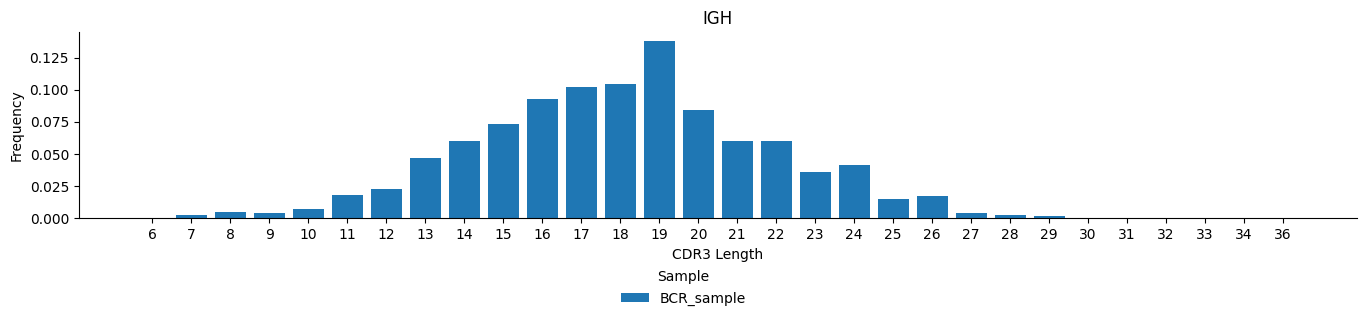

In [18]:
# Показываем распределения длин для отдельных образцов без разбиения по группам.
rsplot.cdr3_length_distributions(cdr3_len_distribs)

Распределение имеет выраженный максимум, при этом короткие и длинные варианты CDR3 встречаются значительно реже. Это свидетельствует о преобладании последовательностей средней длины в исследуемом репертуаре

## Segment usage

### V-usage

In [19]:
# Считаем частоту использования каждого V-сегмента в каждом функциональном репертуаре.
v_usage = stats.calc_segment_usage(clonosets, segment="v", cl_filter=func_filter, table="long")
v_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,v,usage
0,BCR_sample,IGH,IGHV1-17,0.000011
1,BCR_sample,IGH,IGHV1-18,0.065845
2,BCR_sample,IGH,IGHV1-2,0.010684
3,BCR_sample,IGH,IGHV1-24,0.003837
4,BCR_sample,IGH,IGHV1-3,0.020298
5,BCR_sample,IGH,IGHV1-45,0.000368
6,BCR_sample,IGH,IGHV1-46,0.024714
7,BCR_sample,IGH,IGHV1-58,0.002264
8,BCR_sample,IGH,IGHV1-68,0.000011
9,BCR_sample,IGH,IGHV1-69,0.024391


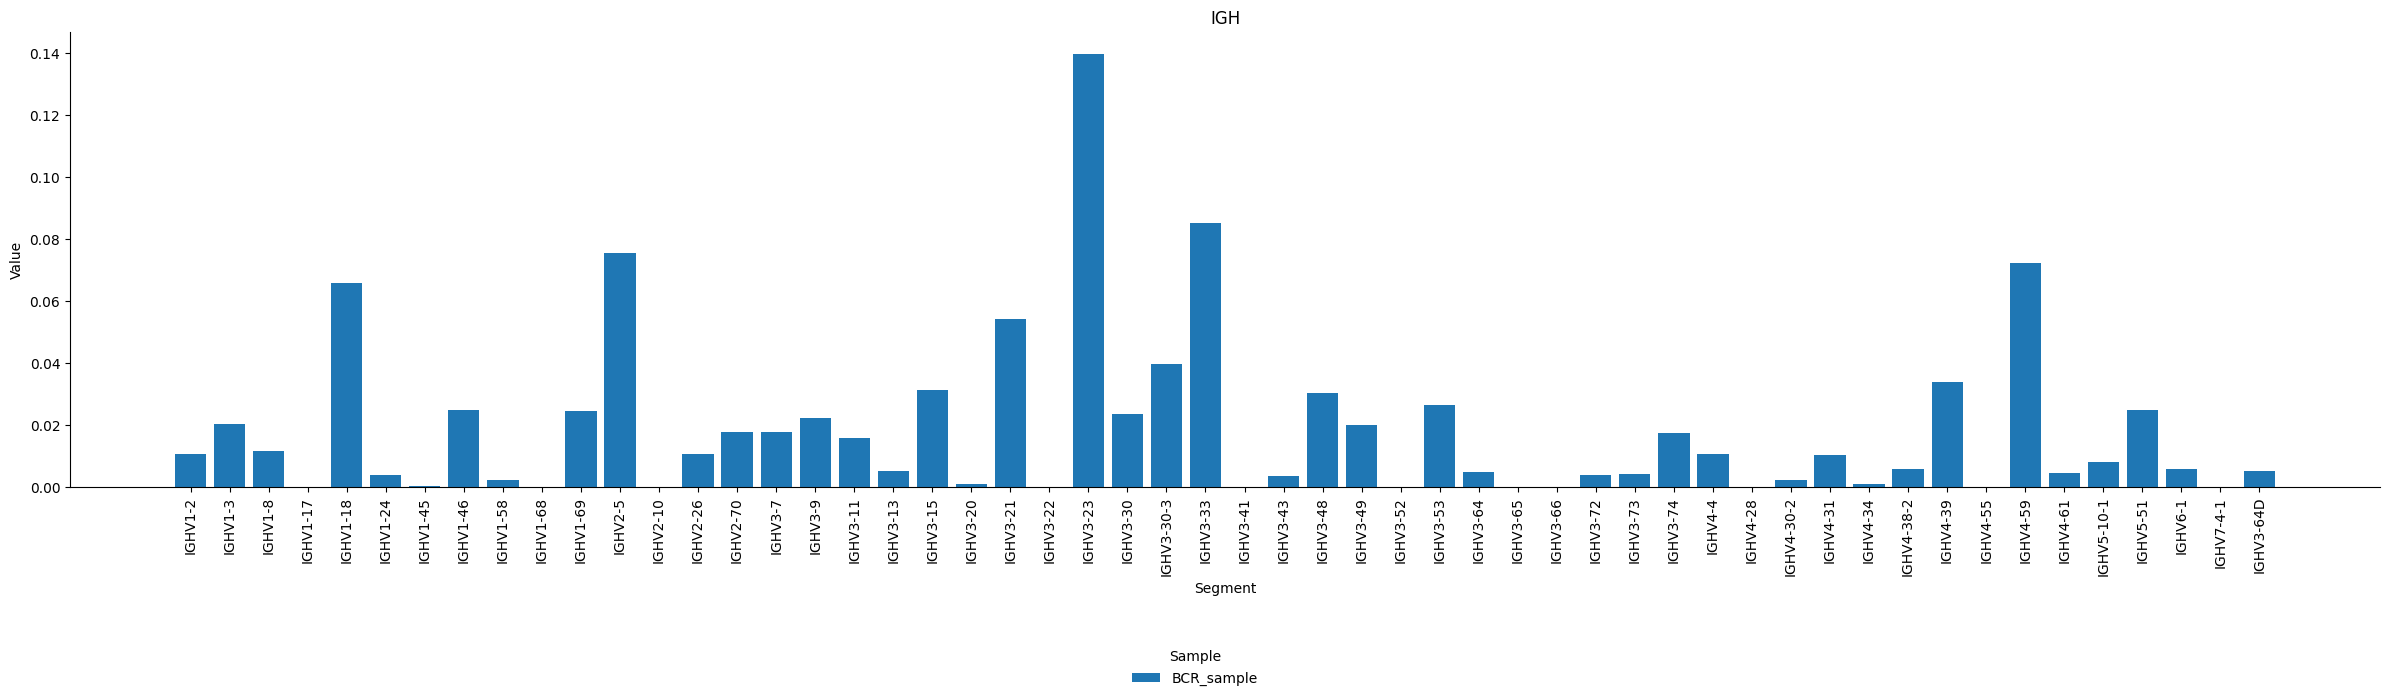

In [20]:
rsplot.segment_usage(v_usage, plot_type="barplot", height=7)

### J-usage

In [21]:
# Считаем частоты использования J-сегментов вместо V-сегментов.
j_usage = stats.calc_segment_usage(clonosets, segment="j", cl_filter=func_filter)
j_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,j,usage
0,BCR_sample,IGH,IGHJ1,0.013428
1,BCR_sample,IGH,IGHJ2,0.020900
2,BCR_sample,IGH,IGHJ3,0.137635
3,BCR_sample,IGH,IGHJ4,0.456934
4,BCR_sample,IGH,IGHJ5,0.100028
5,BCR_sample,IGH,IGHJ6,0.271076


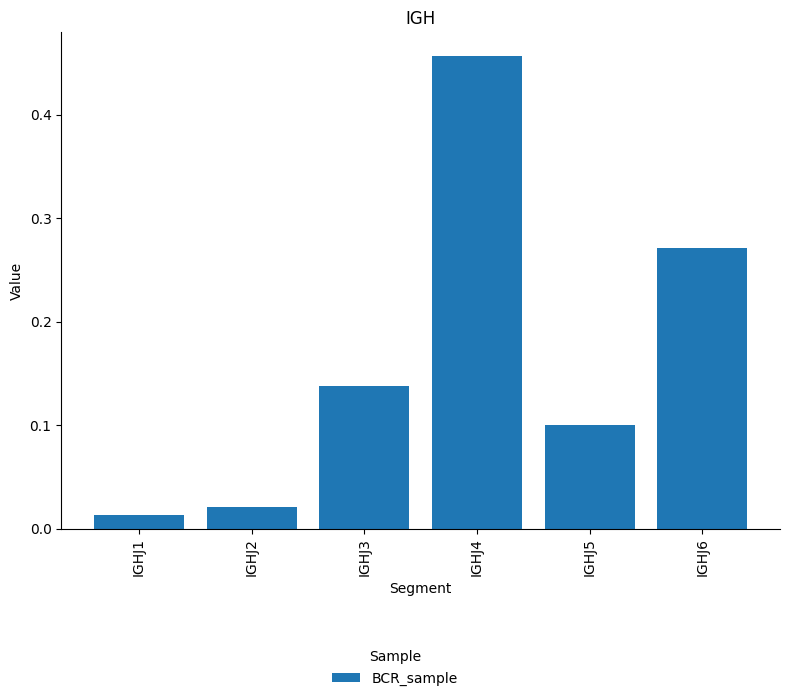

In [22]:
# Отображаем J-usage по экспериментальным группам.
rsplot.segment_usage(j_usage, plot_type="barplot", height=7)

Анализ IGH-репертуара показал неравномерное распределение V- и J-генов.

Среди V-генов наиболее представлен IGHV3-23 (около 14%). Среди J-генов преобладает IGHJ4 (около 46%)

Таким образом, в исследуемом BCR-репертуаре наблюдается преимущественное использование отдельных V- и J-сегментов, но по одному образцу нельзя сделать вывод о том, связано ли это распределение с антиген-специфическим ответом

## Convergence

In [23]:
# # Функция делает случайные повторы: фиксируем seed для воспроизводимости.
convergence = stats.calc_convergence(
    clonosets,
    cl_filter=func_filter,
    seed=42,
    cpu=2,
    verbose=True
)

convergence

CalcConvergence: for the most honest comparison, use a filter with equal downsampling for all samples. This is preferred to top=N filters and much preferred to calculations without normalization.
CalcConvergence settings: seed=42, downsample=None, top=None, iterations=3
Using 2 cores
CalcConvergence |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,convergence,convergence_v,convergence_vj
0,BCR_sample,IGH,1.00773,1.007489,1.007415


Все показатели близки к 1, что свидетельствует о низкой конвергенции (большинство уникальных аминокислотных последовательностей CDR3 представлены одним нуклеотидным вариантом)

## Diversity stats

In [24]:
# Считаем несколько индексов альфа-разнообразия на одинаковой глубине.
# # iterations=3 повторяет случайный выбор; это не три биологических образца.
diversity_stats = stats.calc_diversity_stats(clonosets,
                                             cl_filter=func_filter, seed=123, cpu=2,
                                             iterations=3,
                                             drop_small_samples=False,
                                             verbose=True
                                            )
diversity_stats

CalcDiversityStats: for the most honest comparison, use a filter with equal downsampling for all samples. This is preferred to top=N filters and much preferred to calculations without normalization.
CalcDiversityStats settings: seed=123, downsample=None, top=None, iterations=3
Using 2 cores
CalcDiversityStats |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,diversity,norm_shannon_wiener,clonality,shannon_wiener,chao1,richness,ace,goods_coverage,d50,simpson,inverse_simpson,gini_simpson,berger_parker,gini_coefficient
0,BCR_sample,IGH,36416.0,0.887917,0.112083,9.325583,73101.501839,36416.0,81167.428485,0.727173,0.067141,0.000501,1994.658513,0.999499,0.007193,0.539796


Полученные значения указывают на достаточно равномерное распределение частот клонотипов и невысокую клональность. Оценка богатства Chao1 (около 73 102) превышает наблюдаемое разнообразие, что предполагает наличие дополнительных редких клонотипов, не обнаруженных при текущей глубине секвенирования

## Rarefaction

In [25]:
# Для образца вычисляем богатство при нескольких глубинах наблюдений.
rarefaction_points_bcr = stats.calc_rarefaction_curve(clonosets, cl_filter=clf.Filter(functionality="f", by_umi=True))
rarefaction_points_bcr

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcRarefactionPoints |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,rarefaction_depth,diversity
0,BCR_sample,IGH,32,31.666667
1,BCR_sample,IGH,100,98.000000
2,BCR_sample,IGH,316,293.333333
3,BCR_sample,IGH,1000,856.333333
4,BCR_sample,IGH,3162,2346.666667
5,BCR_sample,IGH,10000,6207.000000
6,BCR_sample,IGH,31623,16467.000000
7,BCR_sample,IGH,89665,36416.000000


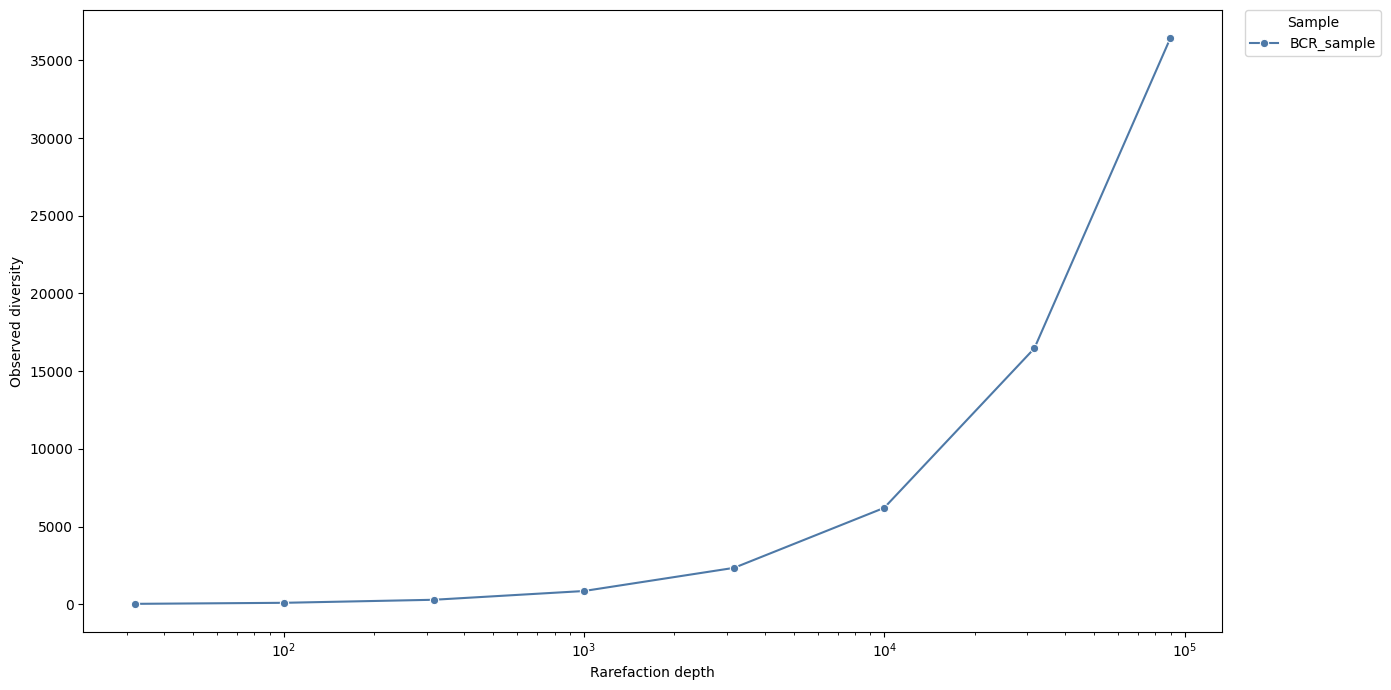

In [26]:
# Строим rarefaction с логарифмической шкалой глубины для обзора широкого диапазона.
rsplot.rarefaction_curve(rarefaction_points_bcr, log_x=True, aspect=2, height=7)

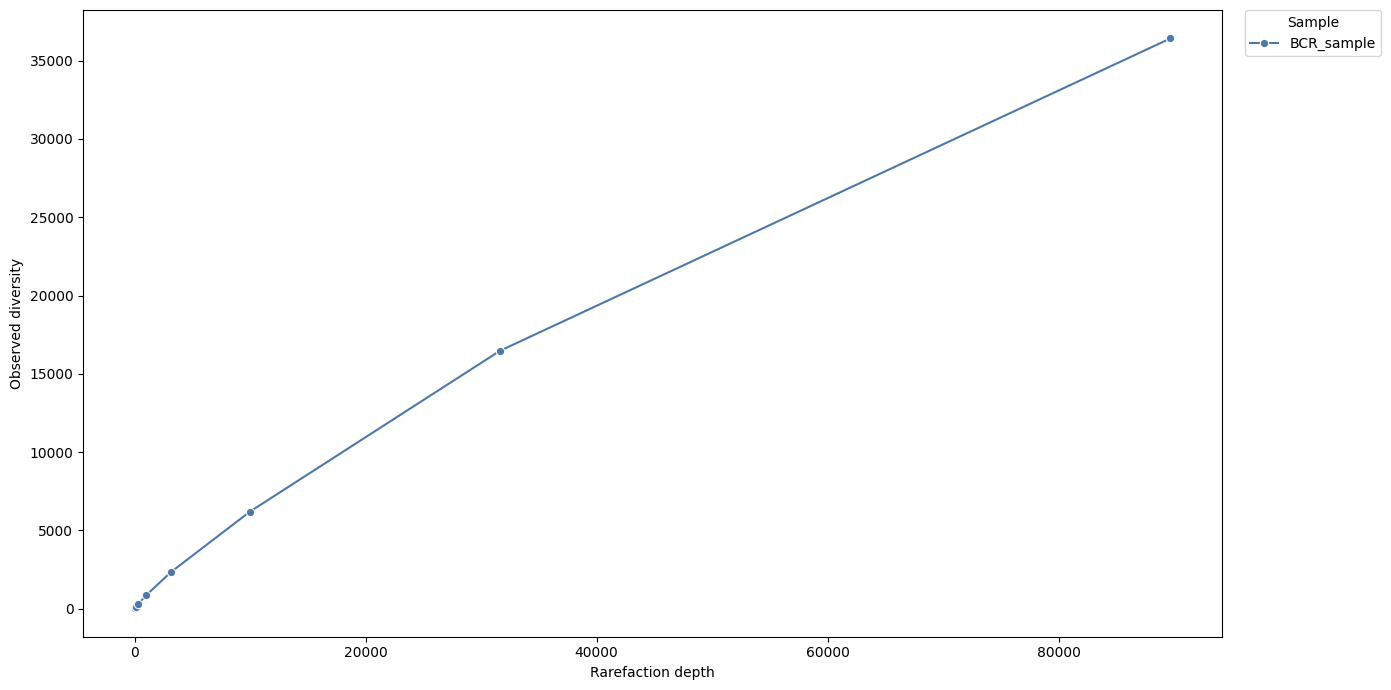

In [27]:
# Строим ту же кривую с обычной шкалой глубины для оценки формы роста.
rsplot.rarefaction_curve(rarefaction_points_bcr, log_x=False, aspect=2, height=7)

Кривая разрежения IGH-репертуара показывает постепенное увеличение числа обнаруженных клонотипов с ростом глубины выборки. Кривая не достигает выраженного плато, что свидетельствует о неполном охвате разнообразия BCR-репертуара (возможно увеличение глубины секвенирования позволило бы выявить дополнительные редкие клонотипы)

## Clustering

### Create clusters

In [28]:
# Создаём пустой объект, в котором будут храниться клонотипы и связи между ними.
clusters = clustering.Clusters()
clusters

Clusters state:
  State: empty
Clonotypes: not read
Clusters: not created
Metadata: not added
Node Pgen: not calculated
ALICE: not calculated

In [29]:
# Загружаем отфильтрованные клонотипы всех выбранных образцов в объект кластеризации.
clusters.read_from_clonosets_df(clonosets, cl_filter=top_filter)

Pooled 4000 clonotypes from 1 samples


In [30]:
# Соединяем близкие по CDR3aa клонотипы с одинаковым V-геном, допуская один mismatch.
clusters.create_clusters(overlap_type='aaV', mismatches=1)

Nodes list created: 4000 nodes
Using all available worker processes by default. Set cpu=1 or another integer to change this.
Find neighbour clonotypes |##################################################| 582/582 tasks processed
found 1617 edges
-----------------------------
NexworkX graph created
Found 191 clusters (2 or more nodes) and 3391 single nodes. Total: 3582


In [31]:
# Преобразуем граф кластеризации в обычную таблицу для просмотра и фильтрации.
clusters_df = clusters.as_dataframe()
clusters_df

,cluster_no,node_id,cdr3aa,v,j,cdr3nt,sample_id,freq,count,isotype,n_neighbours
0,0,49,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGACCGCCGTACTGGTCTTTGGAGTGGTTATGGGTACA...,BCR_sample,0.002536,125,IgG1,39
1,0,203,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGGCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,BCR_sample,0.001095,54,IgG1,39
2,0,121,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGCCGGACTGGTCTTTGGAGTGGTTATGGGTACA...,BCR_sample,0.001582,78,IgG1,39
3,0,344,CARDRRTGVWSGYGYMDLW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGCCGTACTGGTGTTTGGAGTGGTTATGGGTACA...,BCR_sample,0.000730,36,IgG1,6
4,0,107,CARDRRTGLWSGYGYMDVW,IGHV3-33,IGHJ6,TGTGCGAGAGATCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,BCR_sample,0.001663,82,IgG3,39
...,...,...,...,...,...,...,...,...,...,...,...
3995,3577,2970,CVTLVVTDGVAFDYW,IGHV3-74,IGHJ4,TGTGTAACTCTAGTGGTGACTGATGGGGTCGCATTTGACTACTGG,BCR_sample,0.000061,3,IgM,0
3996,3578,2054,CVVSQVRW,IGHV1-8,IGHJ4,TGTGTGGTATCCCAAGTTAGGTGG,BCR_sample,0.000061,3,IgM,0
3997,3579,3846,CVWEYDAFDIW,IGHV3-33,IGHJ3,TGTGTCTGGGAATATGATGCTTTTGATATCTGG,BCR_sample,0.000041,2,IgM,0
3998,3580,1500,CWEIFGPW,IGHV4-39,IGHJ5,TGTTGGGAGATTTTTGGCCCCTGG,BCR_sample,0.000081,4,IgD,0


In [32]:
# Считаем характеристики кластеров: число вершин, рёбер, размер и консенсус.
cluster_properties = clusters.properties()
cluster_properties

Using all available worker processes by default. Set cpu=1 or another integer to change this.
Calculating cluster properties |##################################################| 3582/3582 clusters processed


,cluster_no,cluster_id,nodes,edges,total_count,diameter,density,eccentricity,concensus_cdr3aa,concensus_cdr3nt,concensus_v,concensus_j
0,0,cluster_0,46,797,3941,4,0.770048,2.369565,CARDRRTGLWSGYGYMDVW,TGTGCGAGAGATCGCCGTACTGGTCTTTGGAGTGGTTATGGCTACA...,IGHV3-33,IGHJ6
1,1,cluster_1,23,102,457,6,0.403162,4.217391,CAKLQGIFWLWQPNRAGGADYW,TGTGCGAAACTTCAGGGAATATTTTGGTTGTGGCAACCCAACCGGG...,IGHV3-30,IGHJ4
2,2,cluster_2,13,38,697,3,0.487179,2.769231,CARFVRGAFPPYYYYMDVW,TGTGCGAGATTTGTACGTGGAGCTTTTCCCCCCTACTACTACTACA...,IGHV1-18,IGHJ6
3,3,cluster_3,11,53,502,2,0.963636,1.272727,CAHRPGIALVGAGAFRFDPW,TGTGCACACAGGCCGGGTATAGCACTGGTTGGTGCTGGTGCGTTCC...,IGHV2-5,IGHJ5
4,4,cluster_4,11,31,145,3,0.563636,2.454545,CARSPRRFDFWSGFYSYYFDYW,TGTGCGAGATCCCCCCGGCGTTTCGATTTTTGGAGTGGTTTTTATT...,IGHV3-21,IGHJ4
...,...,...,...,...,...,...,...,...,...,...,...,...
3577,3577,cluster_3577,1,0,3,0,0.000000,0.000000,CVTLVVTDGVAFDYW,TGTGTAACTCTAGTGGTGACTGATGGGGTCGCATTTGACTACTGG,IGHV3-74,IGHJ4
3578,3578,cluster_3578,1,0,3,0,0.000000,0.000000,CVVSQVRW,TGTGTGGTATCCCAAGTTAGGTGG,IGHV1-8,IGHJ4
3579,3579,cluster_3579,1,0,2,0,0.000000,0.000000,CVWEYDAFDIW,TGTGTCTGGGAATATGATGCTTTTGATATCTGG,IGHV3-33,IGHJ3
3580,3580,cluster_3580,1,0,4,0,0.000000,0.000000,CWEIFGPW,TGTTGGGAGATTTTTGGCCCCTGG,IGHV4-39,IGHJ5


In [33]:
# Смотрим сводное представление объекта кластеров.
clusters

Clusters state:
  Completed: clonotypes read, clusters created
Clonotypes:
    source: clonosets_df
    clonotypes: 4000
    samples: 1
    input_samples: 1
    filter:
      name: default_filter
      functionality: f
      downsample_size: None
      top: 4000
      by_umi: True
      mix_tails: True
      seed: 100
      count_threshold: None
      unweight: False
      recount_fractions: True
      white_list: []
      black_list: []
      pool_by: 
      convert: True
      ignore_small_clonosets: False
      retain_alleles: False
Graph: 4000 nodes and 1617 edges
Clusters: 191 clusters (2 or more nodes) and 3391 single nodes. Total: 3582
Clustering parameters:
    method: mismatches
    overlap_type: aaV
    mismatches: 1
Metadata: not added
Node Pgen: not calculated
ALICE: not calculated

### Plot clusters

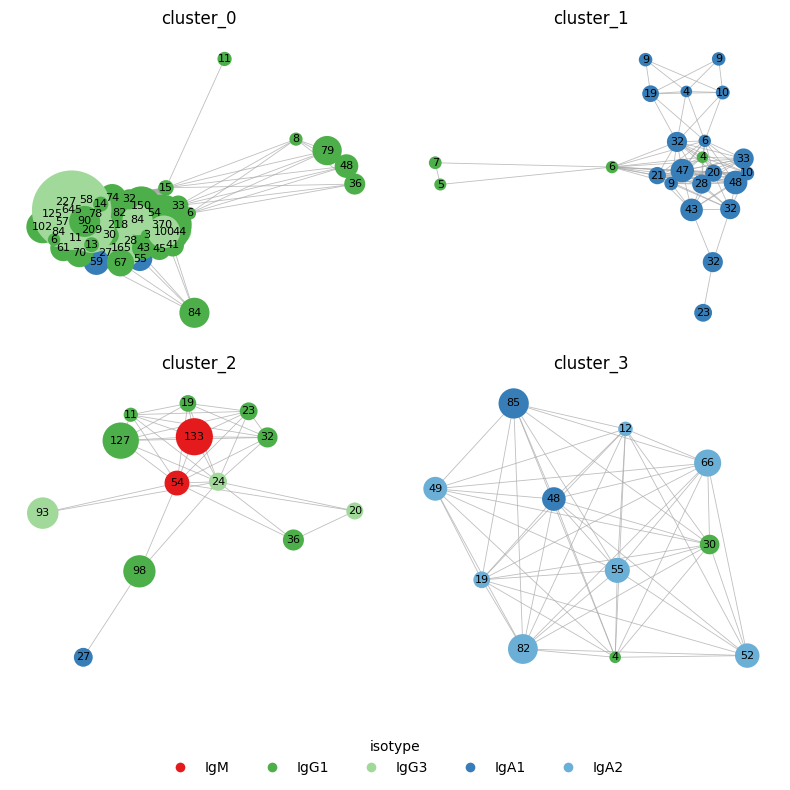

In [34]:
# Рисуем кластеры 20–29; цвет кодирует группу, размер узла — его count.
clusters.plot_cluster([0, 1, 2, 3], color="isotype", label="count", log_scaled=False, size="count", linear_scale=5)

Для кластеризации были отобраны 4000 наиболее представленных продуктивных IGH-клонотипов по UMI. В отличие от семинара, где использовалось даунсэмплирование нескольких TCR-образцов, здесь анализируется один BCR-образец,поэтому был применён фильтр `top_filter`, ограничивающий число последовательностей для кластеризации

Сам метод кластеризации остался прежним (клонотипы объединялись по сходству аминокислотных последовательностей CDR3 с учётом V-гена и допущением одного несовпадения). Среди 4000 отобранных IGH-клонотипов выявлен 191 кластер, содержащий две и более последовательности, и 3391 одиночный клонотип. Крупнейший кластер объединяет 46 клонотипов. Таким образом, большинство последовательностей не образуют группы по заданному критерию сходства

Для визуализации были выбраны четыре крупнейших кластера (0–3). Вместо окраски по экспериментальным группам использовалась окраска по изотипам иммуноглобулинов (IgM, IgG, IgA). На графике видно, что некоторые кластеры содержат клонотипы разных изотипов - это свидетельствует о сходстве их CDR3-последовательностей, однако не позволяет однозначно установить общее клональное происхождение или антигенную специфичность

**Ограничение:** поскольку анализировались только 4000 наиболее представленных клонотипов, результаты кластеризации не отражают весь IGH-репертуар

##Дополнительно: Распределение классов антител

In [35]:
#рассчитаем использование C-сегментов (изотипов)
c_usage = stats.calc_segment_usage(clonosets, segment="c", cl_filter=func_filter, table="long")

c_usage

Using all available worker processes by default. Set cpu=1 or another integer to change this.
CalcSegmentUsage |##################################################| 1/1 calcultaion(s) processed


,sample_id,chain,c,usage
0,BCR_sample,IGH,<NA>,0.000056
1,BCR_sample,IGH,IGHA1,0.114638
2,BCR_sample,IGH,IGHA2,0.027145
3,BCR_sample,IGH,IGHD,0.215636
4,BCR_sample,IGH,IGHG1,0.186059
5,BCR_sample,IGH,IGHG2,0.014242
6,BCR_sample,IGH,IGHG3,0.032621
7,BCR_sample,IGH,IGHG4,0.000167
8,BCR_sample,IGH,IGHGP,0.000011
9,BCR_sample,IGH,IGHM,0.409424


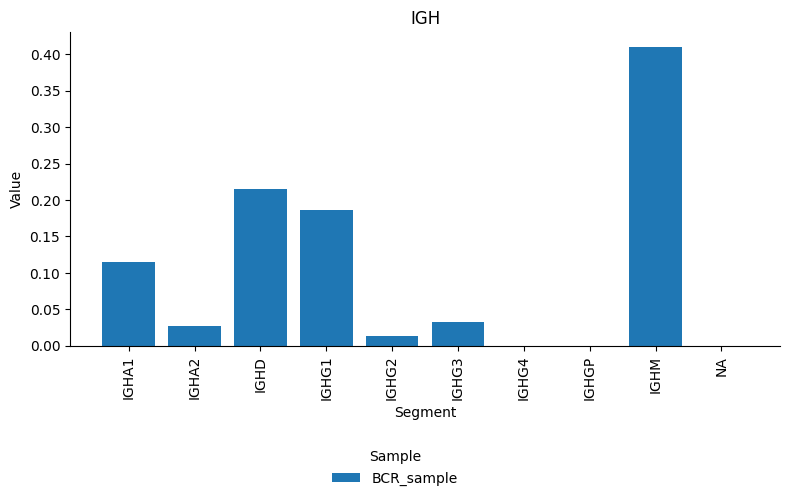

In [36]:
rsplot.segment_usage(c_usage, plot_type="barplot", height=5)

Для продуктивных IGH-клонотипов рассчитаем распределение изотипов иммуноглобулинов на основе использования C-сегментов с учётом UMI.

В отличие от TCR, B-клеточные рецепторы могут принадлежать к разным классам иммуноглобулинов (IgM, IgD, IgG, IgA, IgE) Распределение изотипов может отражать особенности состава В-клеточной популяции и переключения классов иммуноглобулинов, однако само по себе не позволяет определить антигенную специфичность клонотипов

В исследуемом IGH-репертуаре преобладают изотипы IgM (40,94%) и IgD (21,56%). Наличие IgG- и IgA-последовательностей согласуется с присутствием В-клеток, прошедших переключение классов иммуноглобулинов

## Вывод

Анализ BCR-репертуара тяжёлой цепи иммуноглобулинов (IGH) выявил 36 416 продуктивных клонотипов, что свидетельствует о значительном разнообразии исследуемого репертуара. Нормированный индекс Шеннона и относительно низкая клональность (0,112) указывают на отсутствие выраженного доминирования небольшого числа клонотипов, при  этом кривая разрежения не достигает плато, что предполагает наличие дополнительного разнообразия, не охваченного текущей глубиной секвенирования

Кластеризация выявила группы близких CDR3-последовательностей, в том числе представленных разными изотипами - это может отражать процессы диверсификации В-клеточных рецепторов, однако для подтверждения общего клонального происхождения необходим дополнительный анализ

Таким образом, исследуемый образец характеризуется разнообразным и неоднородным BCR-репертуаром с признаками присутствия В-клеток, прошедших антиген-зависимое созревание. При этом анализ одного образца не позволяет установить антигенную специфичность рецепторов или сделать выводы об особенностях иммунного ответа на конкретную инфекцию